## 1. Fase 1 - Comprensión del negocio

### 1.1 Contexto del problema
Un banco realiza campañas de marketing directo (llamadas telefónicas) para ofrecer un **depósito a plazo** a sus clientes. Contactar a todos los clientes es costoso y poco eficiente; identificar a quienes tienen mayor probabilidad de aceptar permite enfocar los recursos comerciales de la campaña.

### 1.2 Objetivo general
Construir un modelo de **clasificación** que estime si un cliente contratará un depósito a plazo (`y`: yes/no) para apoyar la priorización de clientes en campañas de marketing.

### 1.3 Objetivos específicos
- Identificar las variables que se asocian a la contratación del depósito.
- Estimar la probabilidad de contratación de cada cliente.
- Evaluar el desempeño del modelo con datos que no vio durante el entrenamiento (conjunto de prueba).

Alumnos : Tabatha Gamboa - Fabian Parraguez

### 1.4 Criterios de éxito

**Éxito de negocio:**
- Aumentar la tasa de conversión contactando primero a los clientes con mayor probabilidad de contratar.
- Reducir el costo comercial evitando llamadas a clientes con baja probabilidad.

**Éxito técnico:**
- `Recall` de la clase `yes` mayor o igual a 0.50.
- `ROC-AUC` mayor o igual a 0.90 como meta de capacidad discriminante.

### 1.5 Supuestos y restricciones
- Se asume que `bank-full.csv` representa adecuadamente a los clientes de la campaña.
- El target es binario (`y`: yes/no) y está desbalanceado; se priorizan Recall, ROC-AUC, Precision y F1.
- `duration`, `campaign`, `day`, `month` y `contact` describen el contacto actual. Como el objetivo es priorizar antes de la campaña, se excluyen porque no están disponibles de antemano.
- No se cuenta con costos reales de campaña; las métricas técnicas no sustituyen una evaluación económica.

### 1.6 Iteración del Taller 6
El Taller 6 desarrolla **una sola iteración completa de CRISP-DM** para el examen: preparación de datos, entrenamiento y evaluación de un Random Forest con balanceo de clases, interpretación de resultados y plan de despliegue.

## 2. Fase 2 - Comprensión de los datos

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, roc_auc_score, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, recall_score, precision_score, f1_score
)

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

In [2]:
# Cargar el dataset bank-full.csv
df = pd.read_csv('../Data/bank-full.csv', sep=';')

print('Dimensiones:', df.shape)
print('Columnas:')
print(df.columns.tolist())

df.head()

Dimensiones: (45211, 17)
Columnas:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
# Estructura y tipos de datos
df.info()

In [4]:
# Calidad de datos: valores faltantes y duplicados
missing = df.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]

print('Valores faltantes por columna (solo > 0):')
print(missing if len(missing) > 0 else 'No se detectan nulos explícitos.')

print('\nDuplicados totales:', df.duplicated().sum())

Valores faltantes por columna (solo > 0):
No se detectan nulos explícitos.


y
no     39922
yes     5289
Name: count, dtype: int64
y
no     0.883
yes    0.117
Name: proportion, dtype: float64


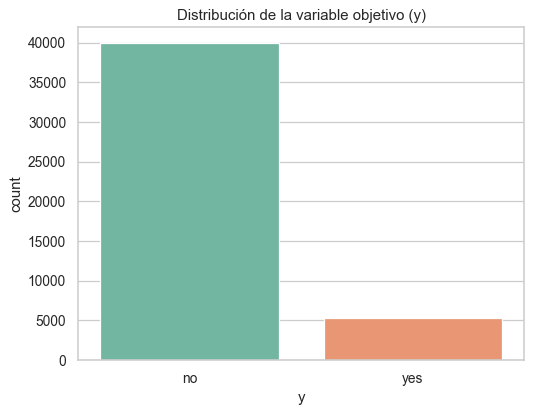

In [5]:
# Revisión de la variable objetivo
print(df['y'].value_counts(dropna=False))
print(df['y'].value_counts(normalize=True, dropna=False).round(4))

sns.countplot(data=df, x='y', palette='Set2')
plt.title('Distribución de la variable objetivo (y)')
plt.show()

**Explicación del gráfico:** el gráfico de barras muestra cuántos clientes contrataron el depósito a plazo (`yes`) y cuántos no (`no`). La barra de `no` es mucho más alta: solo cerca del 12% de los clientes contrata. Esto significa que las clases están **desbalanceadas**, por lo que la Accuracy por sí sola no es una buena medida y se deben revisar Precision, Recall y F1 de la clase `yes`.

In [6]:
# Resumen descriptivo de variables numéricas
df.describe(include=[np.number]).T

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


### 2.1 Hallazgos iniciales de la fase de comprensión de datos
- El dataset contiene **45.211 registros** y **17 columnas** (16 variables predictoras y el target `y`).
- El problema es de **clasificación binaria** (`y`) y existe **desbalance de clases**: aproximadamente 88% `no` y 12% `yes`.
- No hay valores nulos ni filas duplicadas.
- Las variables categóricas (`job`, `marital`, `education`, `default`, `housing`, `loan`, `contact`, `month`, `poutcome`) deberán codificarse antes del modelado.
- Las variables numéricas tienen escalas muy distintas (por ejemplo `balance` vs `age`), por lo que se estandarizarán.
- `duration`, `campaign`, `day`, `month` y `contact` describen el contacto actual y no estan disponibles al priorizar clientes antes de la campana; se excluyen del modelo.

## 3. Fase 3 - Preparación de los datos

Se convierte el target (`yes` = 1, `no` = 0), se separan variables numéricas y categóricas y se divide el conjunto en entrenamiento (80%) y prueba (20%) de forma estratificada. Se excluyen `duration`, `campaign`, `day`, `month` y `contact`: no están disponibles al priorizar clientes antes de la campaña. La codificación y el escalado se ajustan dentro del `Pipeline`, usando únicamente entrenamiento.

In [7]:
# Target binario (yes = 1, no = 0) y variables disponibles antes de la campaña
# Se excluyen variables conocidas durante o después de los contactos actuales.
y = df['y'].map({'yes': 1, 'no': 0})
excluded_cols = ['y', 'duration', 'campaign', 'day', 'month', 'contact']
X = df.drop(columns=excluded_cols)

num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()
print('Variables numéricas:', num_cols)
print('Variables categóricas:', cat_cols)
print('Dimensiones de X:', X.shape)
print('Valores faltantes en y:', y.isna().sum())

Variables numéricas: ['age', 'balance', 'pdays', 'previous']
Variables categóricas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'poutcome']
Dimensiones de X: (45211, 11)


In [8]:
# División estratificada en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print('Entrenamiento:', X_train.shape)
print('Prueba:', X_test.shape)
print('Proporción yes en entrenamiento:', round(y_train.mean(), 4))
print('Proporción yes en prueba:', round(y_test.mean(), 4))

Entrenamiento: (36168, 11)
Prueba: (9043, 11)
Proporción yes en entrenamiento: 0.117


In [9]:
# ColumnTransformer: escalado numérico y One-Hot Encoding categórico
# handle_unknown='ignore' permite procesar categorías nuevas en datos futuros.
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)

preprocessor

,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,copy,True
,with_mean,True
,with_std,True


## 4. Fase 4 - Modelado

### Iteración única - Random Forest con balanceo

Se entrena un único `RandomForestClassifier` con `class_weight='balanced'` para abordar el desbalance de clases. El preprocesamiento y el clasificador quedan integrados en un `Pipeline`. Los hiperparámetros se fijan antes de evaluar el conjunto de prueba.

### Modelo de la iteración - Random Forest

Se usa un solo clasificador para este taller. El peso balanceado compensa el desbalance de la clase `yes`; el conjunto de prueba se reserva para la evaluación final.

In [10]:
# Iteración única: Random Forest con class_weight='balanced'
model_pipeline = Pipeline(steps=[
    ('preprocesamiento', preprocessor),
    ('modelo', RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        class_weight='balanced',
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

model_pipeline.fit(X_train, y_train)

,steps,"[('preprocesamiento', ...), ('modelo', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


,Precision (yes),Recall (yes),F1 (yes),ROC-AUC
Random Forest con balanceo,0.2962,0.5028,0.3728,0.7281


## 5. Fase 5 - Evaluación

Se evalúa el único modelo en el conjunto de prueba, que no participó en el entrenamiento. Se revisan Precision, Recall, F1 de la clase `yes`, ROC-AUC y la matriz de confusión para contrastar el resultado con los criterios definidos en la Fase 1.

In [11]:
# Evaluación del único modelo en el conjunto de prueba
y_pred = model_pipeline.predict(X_test)
y_proba = model_pipeline.predict_proba(X_test)[:, 1]

print('=== Random Forest con balanceo: conjunto de prueba ===')
print(classification_report(y_test, y_pred, target_names=['no', 'yes'], zero_division=0))

roc_auc = roc_auc_score(y_test, y_proba)
results_df = pd.DataFrame([{
    'Precision (yes)': precision_score(y_test, y_pred, zero_division=0),
    'Recall (yes)': recall_score(y_test, y_pred, zero_division=0),
    'F1 (yes)': f1_score(y_test, y_pred, zero_division=0),
    'ROC-AUC': roc_auc,
}], index=['Random Forest con balanceo'])

display(results_df.round(4))
print(f'\nCriterios: Recall (yes) >= 0.50; ROC-AUC >= 0.90')
print(f'Recall: {"cumple" if results_df.iloc[0]["Recall (yes)"] >= 0.50 else "no cumple"}')
print(f'ROC-AUC: {"cumple" if roc_auc >= 0.90 else "no cumple"}')

=== Random Forest con balanceo: conjunto de prueba ===
              precision    recall  f1-score   support

          no       0.93      0.84      0.88      7985
         yes       0.30      0.50      0.37      1058

    accuracy                           0.80      9043
   macro avg       0.61      0.67      0.63      9043
weighted avg       0.85      0.80      0.82      9043


Criterios: Recall (yes) >= 0.50; ROC-AUC >= 0.90
Recall: cumple


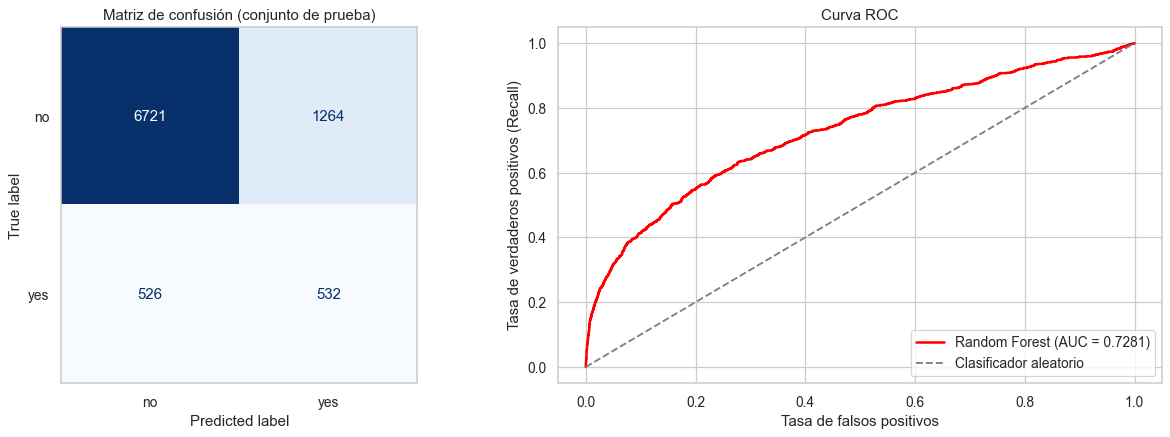

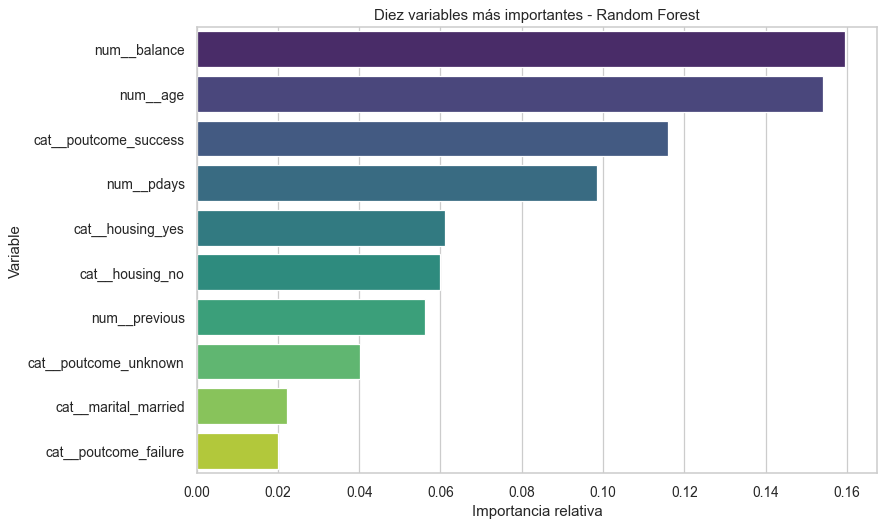

In [12]:
# Matriz de confusión y curva ROC del modelo
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['no', 'yes']).plot(
    ax=axes[0], cmap='Blues', values_format='d', colorbar=False
)
axes[0].set_title('Matriz de confusión (conjunto de prueba)')
axes[0].grid(False)

fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, color='red', lw=2, label=f'Random Forest (AUC = {roc_auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--', label='Clasificador aleatorio')
axes[1].set_xlabel('Tasa de falsos positivos')
axes[1].set_ylabel('Tasa de verdaderos positivos (Recall)')
axes[1].set_title('Curva ROC')
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.show()

**Lectura de los gráficos:** en la matriz de confusión, los falsos negativos son clientes `yes` que el modelo clasificó como `no`; los falsos positivos son clientes `no` clasificados como `yes`. La curva ROC muestra la capacidad de discriminación para distintos umbrales. Como las clases están desbalanceadas, estas visualizaciones se interpretan junto con Precision, Recall y F1 de `yes`, no con Accuracy por sí sola.

In [13]:
# Importancia de variables del único modelo entrenado
rf_model = model_pipeline.named_steps['modelo']
feature_names = model_pipeline.named_steps['preprocesamiento'].get_feature_names_out()
feature_imp_df = pd.DataFrame({
    'Variable': feature_names,
    'Importancia': rf_model.feature_importances_
}).sort_values(by='Importancia', ascending=False).reset_index(drop=True)
top_features = feature_imp_df.head(10)

plt.figure(figsize=(10, 6))
sns.barplot(data=top_features, x='Importancia', y='Variable',
            hue='Variable', palette='viridis', legend=False)
plt.title('Diez variables más importantes - Random Forest')
plt.xlabel('Importancia relativa')
plt.ylabel('Variable')
plt.tight_layout()
plt.show()
print(top_features.to_string(index=False))

### 5.1 Interpretación de resultados e importancia de variables

Se desarrolló una única iteración CRISP-DM con Random Forest y balanceo de clases. En el conjunto de prueba, el modelo obtiene Recall `yes` = 0.5028, Precision `yes` = 0.2962, F1 `yes` = 0.3728 y ROC-AUC = 0.7281. Alcanza por poco el criterio mínimo de Recall (0.50), pero no la meta de ROC-AUC (0.90); por ello, el modelo aún no satisface ambos criterios técnicos.

Las variables de mayor importancia en esta ejecución incluyen `balance`, `age`, `poutcome_success`, `pdays` y `housing`. La importancia describe el uso predictivo del modelo y no demuestra causalidad. `age` requiere especial cuidado y auditoría por segmentos. Se excluyeron `duration`, `campaign`, `day`, `month` y `contact` porque no están disponibles al priorizar clientes antes de la campaña.

#### Recomendaciones estratégicas de negocio

- Considerar el modelo un apoyo experimental para priorizar clientes, no una decisión automática que excluya personas de la campaña.
- Probar la priorización en un piloto controlado y medir conversión, costo por contratación y Recall frente a la estrategia habitual.
- Revisar si `poutcome` y `pdays` permiten formular hipótesis para futuras campañas; una asociación predictiva no demuestra que una intervención cause la contratación.
- Auditar Precision, Recall y tasa de contacto por edad y otros segmentos; no utilizar la edad como regla automática para excluir clientes.
- Antes de un despliegue, mejorar la discriminación y evaluar umbrales junto con los costos reales. La Precision `yes` actual (0.2962) implica que la mayoría de los contactos predichos como positivos no contrata.

## 6. Fase 6 - Despliegue

#### Resumen y plan de despliegue
1. **Conclusión:** se completó una iteración de CRISP-DM con un `Pipeline` que integra preprocesamiento y Random Forest con `class_weight='balanced'`. En prueba, Recall `yes` = 0.5028 y ROC-AUC = 0.7281: cumple la meta de Recall por poco, pero no la meta de ROC-AUC de 0.90.
2. **Despliegue:** no desplegar automáticamente con estos resultados. Como siguiente paso, mejorar y validar el modelo con datos aprobados; antes de conectarlo a Streamlit, versionar el `Pipeline` final y documentar sus 11 variables de entrada.
3. **Uso recomendado:** realizar primero un piloto supervisado para evaluar el beneficio comercial. Las variables del contacto actual excluidas del entrenamiento no deben ser requeridas al puntuar clientes antes de llamar.
4. **Monitoreo:** seguir Recall, Precision, ROC-AUC y métricas de negocio con datos nuevos; vigilar deriva y reentrenar solo después de validar.
5. **Consideraciones éticas:** el modelo refleja asociaciones históricas, no causalidad. Auditar posibles sesgos por edad, empleo y otros segmentos; no usar la predicción como único criterio para negar contacto u ofertas.